# 상품 정보 분류(CH012) 통합 검증 노트북

**스파이크/검증용 코드입니다. 프로덕션 코드가 아닙니다.**

`AI/validation/CLASS/product-info-check/`에 나눠져 있는 모듈(`taxonomy.py` / `dataset.py` /
`classify.py` / `color.py` / `latency.py` / `vlm_control.py` / `evaluate.py`)을 한 곳에서
불러와 **셀 단위로 백엔드·프롬프트 템플릿·분류 모드를 바로 바꿔가며 결과를 확인**할 수 있게
만든 노트북이다. 실행 결과 요약은 `REPORT.md`에 이미 정리돼 있다 — 이 노트북은 그 숫자를
그대로 재현하거나, 값을 바꿔 새 조합을 즉석에서 시험해보는 용도다.

## 사용법

1. **"2. 설정 상수"** 셀의 값(`CATEGORY_BACKEND`/`COLOR_BACKEND`/`TEMPLATE_KEY`/
   `CATEGORY_MODE`/`STRESS_MODE`)만 바꾸고 그 아래 셀들을 다시 실행하면 된다 —
   `model_selection/model_registry.py` 관례와 동일("바꿔 끼울 값을 한곳에 모은다").
2. 각 섹션 끝에는 **"일괄 비교"** 셀이 있다 — 설정 상수를 하나하나 바꿔가며 재실행하는 대신,
   템플릿 3종/백엔드 전체를 한 번에 돌려 표로 비교하고 싶을 때 쓴다.
3. 기본값은 전부 `mock`이라 **torch 등 무거운 의존성 없이도 끝까지 실행된다.** 실백엔드
   (CLIP/SigLIP/Qwen3-VL)를 쓰려면 `validation/requirements-test.txt`를 설치하고 아래
   "0. 의존성 설치" 셀을 실행할 것 — VLM(Qwen3-VL) 쪽은 `transformers>=5.0`이 필요해 이
   requirements 파일과 별도 환경(예: `qual` conda env)이 필요하다(`vlm_control.py` 상단
   docstring 참고).
4. 이 노트북이 참조하는 정답셋(`data/ground_truth.json`)은 11건(실제 사진 10 + synthetic 1)이다
   — 최초 8건 이후 사용자가 테스트용 이미지 3건(`navy_logo.png`/`vintage_t.png`/`black_stain.png`)을
   추가했다. §1이 `dataset.load_ground_truth()`로 매번 새로 읽으므로 **코드 변경 없이 자동
   반영**된다 — 결과 숫자를 과신하지 말 것(N=11도 여전히 작다). `REPORT.md` 맨 위 경고를 먼저
   읽을 것.
5. §7-2는 "CLIP(zero-shot)으로 카테고리+색상을 각자 다른 백엔드로 처리하는 파이프라인" vs
   "Qwen3-VL 하나로 카테고리+색상을 **한 번의 호출**로 같이 처리하는 파이프라인"을 정확도·지연
   양쪽으로 나란히 비교한다.

전체 셀을 mock 기본값(§7의 `RUN_VLM`/`RUN_VRAM_CHECK` 제외)으로 로컬에서 처음부터 끝까지
실행해 오류 없이 도는 것까지 확인했다 — 이 커밋에는 출력을 남기지 않는다(재실행하면 다시
채워진다).

## 0. 의존성 설치 (선택)

실백엔드를 쓸 때만 실행한다. mock만 쓸 거면 건너뛰어도 된다.

In [ ]:
%pip install -q -r ../../requirements-test.txt

## 0-1. GPU/torch 확인 (선택)

CLIP/SigLIP은 CPU로도 돈다(오히려 이 스파이크는 CPU 지연을 재는 게 목적이다). Qwen3-VL
4bit 양자화는 GPU 전제라 CUDA 없으면 §7(VLM 대조군)은 건너뛰게 된다.

In [1]:
try:
    import torch

    print(f"torch          : {torch.__version__}")
    print(f"cuda available : {torch.cuda.is_available()}")
    if torch.cuda.is_available():
        props = torch.cuda.get_device_properties(0)
        print(f"gpu            : {props.name}")
        print(f"total VRAM     : {props.total_memory / 1024**3:.2f} GB")
except ImportError:
    print("torch 미설치 — mock 백엔드만 쓸 수 있다 (그래도 이 노트북은 끝까지 돈다).")


torch          : 2.13.0+cu130
cuda available : True
gpu            : NVIDIA GeForce RTX 4070 Laptop GPU
total VRAM     : 8.00 GB


## 1. 정답셋 로드

`dataset.py`가 스키마 검증까지 한다. `outputs/`(리포트 산출물)는 gitignore 대상이라
`OUTPUT_DIR`은 노트북 실행 중에만 채워진다.

In [2]:
import pandas as pd

from dataset import load_ground_truth, summarize

gt = load_ground_truth()
print(summarize(gt))

real_samples = [s for s in gt.samples if not s.synthetic]
real_images = [s.image_path for s in real_samples]

samples_df = pd.DataFrame(
    [
        {
            "image_file": s.image_file,
            "major": s.major_category,
            "subcategory": s.subcategory,
            "primary_color": s.primary_color,
            "secondary_color": s.secondary_color,
            "shot_type": s.shot_type,
            "synthetic": s.synthetic,
            "needs_human_review": s.needs_human_review,
        }
        for s in gt.samples
    ]
)
samples_df


총 11행 중 유효 11행, 문제 0행
-- 대분류 분포 -- {'BOTTOM': 4, 'TOP': 7}
-- 촬영유형 분포 -- {'flat': 10, 'hanging': 1}
-- 사람 검증 완료 -- 8/11
-- synthetic(실제 사진 아님) -- 1/11


,image_file,major,subcategory,primary_color,secondary_color,shot_type,synthetic,needs_human_review
0,denim.jpg,BOTTOM,DENIM,BLUE,NaN,flat,False,False
1,black_washed.jpg,TOP,T_SHIRT,BLACK,RED,flat,False,False
2,fix.jpg,BOTTOM,DENIM,BLUE,NaN,flat,False,False
3,levis_patch.jpg,BOTTOM,DENIM,BLUE,MULTI,flat,False,False
4,logo_test.jpg,TOP,T_SHIRT,WHITE,NaN,flat,False,False
5,scratch.jpg,BOTTOM,DENIM,BLUE,NaN,flat,False,False
6,shirt_red.png,TOP,SHIRT,WHITE,RED,flat,True,False
7,small_pro.jpg,TOP,T_SHIRT,WHITE,NaN,flat,False,False
8,navy_logo.png,TOP,T_SHIRT,NAVY,NaN,flat,False,True
9,vintage_t.png,TOP,T_SHIRT,KHAKI,BLACK,hanging,False,True


## 2. 설정 상수 — **여기만 바꾸고 아래 셀들을 재실행하면 된다**

| 변수 | 선택지 |
|---|---|
| `CATEGORY_BACKEND` | `classify.CATEGORY_BACKENDS`의 키: `mock` / `clip_vit_b32` / `clip_vit_l14` / `siglip_so400m` / `clip_vit_b32_onnx` |
| `COLOR_BACKEND` | `color.COLOR_BACKENDS`의 키: `mock` / `mean_color` / `kmeans_palette` / `vlm` / `clip_vit_b32` / `clip_vit_l14` / `siglip_so400m` |
| `TEMPLATE_KEY` | `taxonomy.PROMPT_TEMPLATES`의 키: `kr_plain` / `en_clip_style` / `kr_secondhand_flat` |
| `CATEGORY_MODE` | `"one_stage"`(30-way 한 번) / `"two_stage"`(대분류→소분류) |
| `STRESS_MODE` | `latency.py`의 지연 측정 조건: `"none"` / `"synthetic"` / `"external"` |

`REPORT.md`의 실측치는 `CATEGORY_BACKEND="clip_vit_b32"`, `TEMPLATE_KEY="en_clip_style"`,
`CATEGORY_MODE="one_stage"` 조합에서 나온 수치다(top1=0.71) — 그대로 재현하려면 이 값으로
맞추고 실행하면 된다.

In [4]:
from taxonomy import PROMPT_TEMPLATES  # noqa: F401 (선택지 확인용)
from classify import CATEGORY_BACKENDS  # noqa: F401
from color import COLOR_BACKENDS  # noqa: F401

CATEGORY_BACKEND = "clip_vit_b32"  # <- 여기 바꾸면 스왑
COLOR_BACKEND = "clip_vit_b32"  # <- 여기 바꾸면 스왑
TEMPLATE_KEY = "en_clip_style"  # <- 여기 바꾸면 스왑 (kr_plain / en_clip_style / kr_secondhand_flat)
CATEGORY_MODE = "one_stage"  # <- "one_stage" / "two_stage"
STRESS_MODE = "none"  # <- "none"(빠른 스모크) / "synthetic" / "external"

print(f"category backend choices : {list(CATEGORY_BACKENDS)}")
print(f"color backend choices    : {list(COLOR_BACKENDS)}")
print(f"template choices         : {list(PROMPT_TEMPLATES)}")
print(f"현재 설정 -> category={CATEGORY_BACKEND}, color={COLOR_BACKEND}, "
      f"template={TEMPLATE_KEY}, mode={CATEGORY_MODE}, stress={STRESS_MODE}")


category backend choices : ['mock', 'clip_vit_b32', 'clip_vit_l14', 'siglip_so400m', 'clip_vit_b32_onnx']
color backend choices    : ['mock', 'mean_color', 'kmeans_palette', 'vlm', 'clip_vit_b32', 'clip_vit_l14', 'siglip_so400m']
template choices         : ['kr_plain', 'en_clip_style', 'kr_secondhand_flat']
현재 설정 -> category=clip_vit_b32, color=clip_vit_b32, template=en_clip_style, mode=one_stage, stress=none


### 2-1. 프롬프트 템플릿 미리보기 + 커스텀 템플릿 등록 (선택)

`PROMPT_TEMPLATES`는 `taxonomy.py`에 함수로 정의돼 있어서 노트북에서 실제 문구가 안 보인다 —
아래 첫 셀이 각 템플릿이 만드는 실제 프롬프트 텍스트를 그대로 보여준다.

새 프롬프트 문구를 노트북에서 바로 테스트해보고 싶으면 두 번째 셀의 `_custom_template` 함수를
원하는 문구로 고쳐 쓰고 실행한 뒤, 위 §2 설정 상수의 `TEMPLATE_KEY`를 `"custom"`으로 바꿔서
§3부터 다시 실행하면 된다. **`taxonomy.py` 원본 파일은 건드리지 않는다** — 이 커널 프로세스
안에서만 `PROMPT_TEMPLATES`/`MAJOR_PROMPT_TEMPLATES` 딕셔너리에 새 키를 추가하는 것뿐이라,
노트북을 껐다 켜면(커널 재시작) 사라진다.

In [5]:
sample_code = "KNIT"  # 미리보기용 예시 소분류 코드 — 다른 코드로 바꿔봐도 된다
print("=== 기존 템플릿이 실제로 만드는 프롬프트 문구(예: KNIT) ===")
for key, fn in PROMPT_TEMPLATES.items():
    print(f"{key:20s} -> {fn(sample_code)!r}")


=== 기존 템플릿이 실제로 만드는 프롬프트 문구(예: KNIT) ===
kr_plain             -> '니트'
en_clip_style        -> 'a photo of a knit sweater'
kr_secondhand_flat   -> '바닥에 펼쳐놓고 찍은 중고 니트 사진'


In [6]:
import taxonomy


def _custom_template(code: str) -> str:
    # <- 이 문구를 원하는 대로 바꿔서 실행할 것. code에는 소분류 코드(예: "KNIT") 또는
    #    2단계 대분류 코드(예: "TOP")가 들어온다(같은 함수가 양쪽에 다 쓰인다).
    return f"이 사진 속 의류의 종류는 {code}이다"


taxonomy.PROMPT_TEMPLATES["custom"] = _custom_template
taxonomy.MAJOR_PROMPT_TEMPLATES["custom"] = _custom_template

print("커스텀 템플릿 등록 완료 — 위 §2에서 TEMPLATE_KEY = \"custom\" 으로 바꾸고 §3부터 재실행할 것")
print("미리보기:", _custom_template(sample_code))


커스텀 템플릿 등록 완료 — 위 §2에서 TEMPLATE_KEY = "custom" 으로 바꾸고 §3부터 재실행할 것
미리보기: 이 사진 속 의류의 종류는 KNIT이다


## 3. 카테고리 분류 실행 (V2a)

`evaluate.evaluate_category()`가 정답셋(synthetic 제외)에 §2 설정으로 분류기를 돌려
top-1/top-3, 혼동행렬, 대분류·촬영유형별 정확도까지 계산한다.

In [7]:
from evaluate import (
    accuracy_by,
    confusion_matrix,
    evaluate_category,
    majority_baseline_accuracy,
)

category_preds = evaluate_category(gt.samples, CATEGORY_BACKEND, TEMPLATE_KEY, CATEGORY_MODE)

category_df = pd.DataFrame(
    [
        {
            "image_file": p.image_file,
            "truth": p.truth,
            "predicted": p.predicted,
            "score": round(p.score, 3),
            "top3": p.top3,
            "correct_top1": p.correct_top1,
            "correct_top3": p.correct_top3,
            "major": p.major,
            "shot_type": p.shot_type,
            "error": p.error,
        }
        for p in category_preds
    ]
)

n = len(category_preds)
top1 = sum(p.correct_top1 for p in category_preds) / n if n else 0.0
top3 = sum(p.correct_top3 for p in category_preds) / n if n else 0.0
majority_code, majority_acc = majority_baseline_accuracy(gt.samples)

print(f"[{CATEGORY_BACKEND}/{TEMPLATE_KEY}/{CATEGORY_MODE}] top1={top1:.2f} top3={top3:.2f}")
print(f"규칙 baseline(항상 {majority_code}) top1={majority_acc:.2f}  "
      f"-> {'통과' if top1 > majority_acc else '미달'}")
category_df


c:\Users\SSAFY\miniforge3\envs\qual\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 398/398 [00:00<00:00, 18276.83it/s]


[clip_vit_b32/en_clip_style/one_stage] top1=0.70 top3=1.00
규칙 baseline(항상 T_SHIRT) top1=0.60  -> 통과


,image_file,truth,predicted,score,top3,correct_top1,correct_top3,major,shot_type,error
0,denim.jpg,DENIM,DENIM,0.959,"[DENIM, CARGO_PANTS, SHORTS]",True,True,BOTTOM,flat,None
1,black_washed.jpg,T_SHIRT,T_SHIRT,0.743,"[T_SHIRT, SHIRT, SWEATSHIRT]",True,True,TOP,flat,None
2,fix.jpg,DENIM,DENIM,0.907,"[DENIM, CARGO_PANTS, SHORTS]",True,True,BOTTOM,flat,None
3,levis_patch.jpg,DENIM,DENIM,0.870,"[DENIM, CARGO_PANTS, SLACKS]",True,True,BOTTOM,flat,None
4,logo_test.jpg,T_SHIRT,SHIRT,0.547,"[SHIRT, T_SHIRT, SWEATSHIRT]",False,True,TOP,flat,None
5,scratch.jpg,DENIM,DENIM,0.924,"[DENIM, SHORTS, CARGO_PANTS]",True,True,BOTTOM,flat,None
6,small_pro.jpg,T_SHIRT,SHIRT,0.699,"[SHIRT, T_SHIRT, VEST]",False,True,TOP,flat,None
7,navy_logo.png,T_SHIRT,T_SHIRT,0.547,"[T_SHIRT, SHIRT, SWEATSHIRT]",True,True,TOP,flat,None
8,vintage_t.png,T_SHIRT,T_SHIRT,0.661,"[T_SHIRT, SHIRT, JACKET]",True,True,TOP,hanging,None
9,black_stain.png,T_SHIRT,SHIRT,0.788,"[SHIRT, T_SHIRT, JACKET]",False,True,TOP,flat,None


### 3-1. 혼동행렬 + 대분류/촬영유형별 정확도

In [8]:
cm = confusion_matrix(category_preds)
cm_df = pd.DataFrame(cm).fillna(0).astype(int)
cm_df = cm_df.loc[(cm_df.sum(axis=1) > 0), (cm_df.sum(axis=0) > 0)]  # 등장한 라벨만 표시
print("혼동행렬 (행=정답, 열=예측) — 값이 있는 라벨만 표시")
display(cm_df)

print("\n대분류별 정확도")
display(pd.DataFrame(accuracy_by(category_preds, "major")).T)

print("\n촬영유형별 정확도")
display(pd.DataFrame(accuracy_by(category_preds, "shot_type")).T)


혼동행렬 (행=정답, 열=예측) — 값이 있는 라벨만 표시


,T_SHIRT,DENIM
T_SHIRT,3,0
SHIRT,3,0
DENIM,0,4



대분류별 정확도


,n,top1,top3
BOTTOM,4.0,1.0,1.0
TOP,6.0,0.5,1.0



촬영유형별 정확도


,n,top1,top3
flat,9.0,0.666667,1.0
hanging,1.0,1.000000,1.0


### 3-2. 프롬프트 템플릿 x 분류 모드 일괄 비교

설정 상수를 하나하나 바꾸는 대신, `CATEGORY_BACKEND`는 고정한 채 템플릿 3종 x
1단계/2단계 조합 6개를 한 번에 돌려 표로 비교한다. `REPORT.md`의 V2a 표를 그대로
재현한다(백엔드가 `clip_vit_b32`일 때).

In [9]:
rows = []
for template_key in PROMPT_TEMPLATES:
    for mode in ("one_stage", "two_stage"):
        preds = evaluate_category(gt.samples, CATEGORY_BACKEND, template_key, mode)
        n = len(preds)
        rows.append(
            {
                "backend": CATEGORY_BACKEND,
                "template": template_key,
                "mode": mode,
                "n": n,
                "top1": round(sum(p.correct_top1 for p in preds) / n, 3) if n else 0.0,
                "top3": round(sum(p.correct_top3 for p in preds) / n, 3) if n else 0.0,
            }
        )

sweep_df = pd.DataFrame(rows)
sweep_df["beats_majority_baseline"] = sweep_df["top1"] > majority_acc
sweep_df


Loading weights: 100%|██████████| 398/398 [00:00<00:00, 13596.68it/s]


,backend,template,mode,n,top1,top3,beats_majority_baseline
0,clip_vit_b32,kr_plain,one_stage,10,0.1,0.1,False
1,clip_vit_b32,kr_plain,two_stage,10,0.0,0.0,False
2,clip_vit_b32,en_clip_style,one_stage,10,0.7,1.0,True
3,clip_vit_b32,en_clip_style,two_stage,10,0.2,0.2,False
4,clip_vit_b32,kr_secondhand_flat,one_stage,10,0.1,0.4,False
5,clip_vit_b32,kr_secondhand_flat,two_stage,10,0.2,0.3,False
6,clip_vit_b32,custom,one_stage,10,0.4,1.0,False
7,clip_vit_b32,custom,two_stage,10,0.2,0.2,False


## 4. 색상 추출 실행 (V3)

`evaluate.evaluate_color()`가 주 색상/보조 색상 정확도, 팔레트 이탈률, confidence를
계산한다. **`confidence`의 의미는 백엔드마다 다르다**(`color.py` 상단 주석 참고) —
백엔드 간 confidence를 직접 비교하지 말 것.

In [10]:
from evaluate import evaluate_color

color_preds = evaluate_color(gt.samples, COLOR_BACKEND)

color_df = pd.DataFrame(
    [
        {
            "image_file": p.image_file,
            "truth_primary": p.truth_primary,
            "predicted_primary": p.predicted_primary,
            "correct_primary": p.correct_primary,
            "truth_secondary": p.truth_secondary,
            "predicted_secondary": p.predicted_secondary,
            "correct_secondary": p.correct_secondary,
            "confidence": round(p.confidence, 3),
            "off_palette": p.off_palette,
            "major": p.major,
            "error": p.error,
        }
        for p in color_preds
    ]
)

n = len(color_preds)
primary_acc = sum(p.correct_primary for p in color_preds) / n if n else 0.0
print(f"[{COLOR_BACKEND}] 주 색상 정확도={primary_acc:.2f}  "
      f"팔레트 이탈률={sum(p.off_palette for p in color_preds) / n:.2f}")
color_df


Loading weights: 100%|██████████| 398/398 [00:00<00:00, 14225.73it/s]


[clip_vit_b32] 주 색상 정확도=0.20  팔레트 이탈률=0.00


,image_file,truth_primary,predicted_primary,correct_primary,truth_secondary,predicted_secondary,correct_secondary,confidence,off_palette,major,error
0,denim.jpg,BLUE,BLUE,True,NaN,GRAY,False,0.334,False,BOTTOM,None
1,black_washed.jpg,BLACK,GRAY,False,RED,NaN,False,0.520,False,TOP,None
2,fix.jpg,BLUE,SILVER,False,NaN,GRAY,False,0.407,False,BOTTOM,None
3,levis_patch.jpg,BLUE,SKYBLUE,False,MULTI,GRAY,False,0.264,False,BOTTOM,None
4,logo_test.jpg,WHITE,GRAY,False,NaN,WHITE,False,0.536,False,TOP,None
5,scratch.jpg,BLUE,GRAY,False,NaN,BLUE,False,0.223,False,BOTTOM,None
6,small_pro.jpg,WHITE,NAVY,False,NaN,WHITE,False,0.335,False,TOP,None
7,navy_logo.png,NAVY,NAVY,True,NaN,NaN,True,0.849,False,TOP,None
8,vintage_t.png,KHAKI,SILVER,False,BLACK,BROWN,False,0.295,False,TOP,None
9,black_stain.png,BLACK,NAVY,False,NaN,NaN,True,0.719,False,TOP,None


### 4-1. 색상 백엔드 일괄 비교 (`mock` / `mean_color` / `kmeans_palette` / `clip_vit_b32`)

`clip_vit_b32`는 CLIP 이미지 임베딩에 색상 라벨 텍스트를 직접 물어보는 zero-shot이다
(2026-08-02 추가, `color.py`의 `ClipZeroShotColorExtractor`) — 실측(N=10) top1=0.20으로
고전 CV(0.00)보다는 낫지만 VLM(0.60)에는 한참 못 미친다(`REPORT.md` §8 참고). `clip_vit_l14`/
`siglip_so400m`은 로컬에 캐시돼 있지 않으면 다운로드가 필요해 기본적으로 시간이 걸릴 수
있다. `vlm`은 무거운 의존성이 필요해 이 표에서 기본적으로 빼뒀다 — §7에서 `RUN_VLM=True`로
켜면 §7-2 비교표에 `vlm` 행이 나온다.

In [11]:
color_rows = []
for backend_key in ("mock", "mean_color", "kmeans_palette", "clip_vit_b32"):
    try:
        preds = evaluate_color(gt.samples, backend_key)
    except Exception as exc:  # noqa: BLE001 — 실패 격리: 의존성 없는 백엔드만 건너뛴다
        print(f"[{backend_key}] 스킵: {exc}")
        continue
    n = len(preds)
    color_rows.append(
        {
            "backend": backend_key,
            "n": n,
            "primary_accuracy": round(sum(p.correct_primary for p in preds) / n, 3) if n else 0.0,
            "off_palette_rate": round(sum(p.off_palette for p in preds) / n, 3) if n else 0.0,
        }
    )

color_sweep_df = pd.DataFrame(color_rows)
color_sweep_df


Loading weights: 100%|██████████| 398/398 [00:00<00:00, 11714.54it/s]


,backend,n,primary_accuracy,off_palette_rate
0,mock,10,0.0,0.0
1,mean_color,10,0.0,0.0
2,kmeans_palette,10,0.0,1.0
3,clip_vit_b32,10,0.2,0.0


## 5. 지연 실측 (V1)

`STRESS_MODE="synthetic"`은 CPU N-1코어를 인위적으로 포화시킨다(수 분 걸릴 수 있다 —
`REPORT.md`에서 p95가 18초까지 나온 그 조건). 빠르게만 확인하려면 `STRESS_MODE="none"`을
쓴다.

In [12]:
from latency import run_latency_suite

latency_results = run_latency_suite([CATEGORY_BACKEND], real_images, stress_mode=STRESS_MODE)

latency_rows = []
for r in latency_results:
    stats = r.stats()
    latency_rows.append(
        {
            "backend": r.backend,
            "stress": r.stress,
            "load_time_ms": round(r.load_time_s * 1000, 1),
            "p50_ms": round(stats.get("p50", float("nan")), 1),
            "p95_ms": round(stats.get("p95", float("nan")), 1),
            "mean_ms": round(stats.get("mean", float("nan")), 1),
            "peak_mem_mb": round(r.peak_mem_mb, 2),
        }
    )
pd.DataFrame(latency_rows)


Loading weights: 100%|██████████| 398/398 [00:00<00:00, 6760.54it/s]


,backend,stress,load_time_ms,p50_ms,p95_ms,mean_ms,peak_mem_mb
0,clip_vit_b32,idle,9108.9,193.0,213.3,188.7,23.44


## 6. score 분포 → 캘리브레이션 (V4)

§3에서 만든 `category_preds`의 score 분포를 5-bin reliability diagram으로 본다 — 막대가
계단식으로 올라갈수록(구간이 높을수록 정확도도 높을수록) score가 잘 캘리브레이션된 것이다.

In [13]:
def _use_korean_font():
    """matplotlib 제목/축의 한글이 두부 문자로 깨지지 않게 폰트를 잡는다.

    QUAL/qc_shared.py의 동명 헬퍼와 같은 목적이지만, CLASS/product-info-check가 QUAL/을
    직접 import하지 않는다는 패키지 격리 원칙(CH012 §6과 동일 취지)에 따라 그대로 복제해
    둔다 — 10줄짜리 화장용 유틸이라 중복 비용보다 격리 이득이 크다.
    """
    import matplotlib
    from matplotlib import font_manager

    available = {f.name for f in font_manager.fontManager.ttflist}
    for candidate in ("Malgun Gothic", "AppleGothic", "NanumGothic", "Gulim"):
        if candidate in available:
            matplotlib.rcParams["font.family"] = candidate
            matplotlib.rcParams["axes.unicode_minus"] = False
            return


ECE = 0.132
권장 임계값(오답률<=10%): {'threshold': 0.8704960346221924, 'coverage': 4, 'total': 10, 'coverage_ratio': 0.4, 'low_confidence_warning': True}


,bin,n,accuracy,avg_confidence
0,"[0.0, 0.2)",0,0.0,0.000
1,"[0.2, 0.4)",0,0.0,0.000
2,"[0.4, 0.6)",2,0.5,0.547
3,"[0.6, 0.8)",4,0.5,0.723
4,"[0.8, 1.0)",4,1.0,0.915


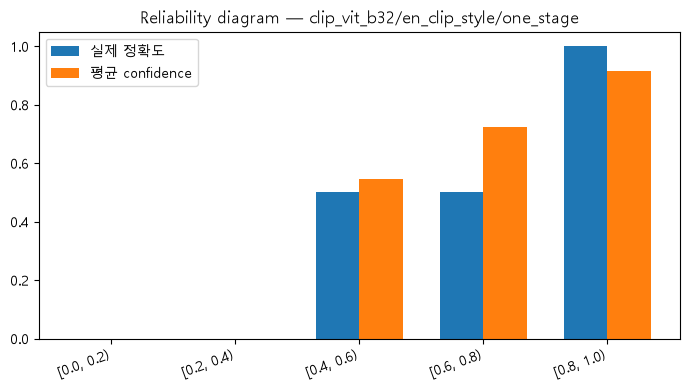

In [14]:
import matplotlib.pyplot as plt

from evaluate import expected_calibration_error, recommend_threshold, reliability_bins

_use_korean_font()

scored = [(p.score, p.correct_top1) for p in category_preds if p.predicted is not None]
bins = reliability_bins(scored, n_bins=5)
bins_df = pd.DataFrame(
    [
        {
            "bin": f"[{b.score_lo:.1f}, {b.score_hi:.1f})",
            "n": b.n,
            "accuracy": round(b.accuracy, 3),
            "avg_confidence": round(b.avg_confidence, 3),
        }
        for b in bins
    ]
)
print(f"ECE = {expected_calibration_error(bins, len(scored)):.3f}")
print(f"권장 임계값(오답률<=10%): {recommend_threshold(scored, max_wrong_rate=0.10)}")
display(bins_df)

fig, ax = plt.subplots(figsize=(7, 4))
x = range(len(bins))
width = 0.35
ax.bar([i - width / 2 for i in x], bins_df["accuracy"], width=width, label="실제 정확도")
ax.bar([i + width / 2 for i in x], bins_df["avg_confidence"], width=width, label="평균 confidence")
ax.set_xticks(list(x))
ax.set_xticklabels(bins_df["bin"], rotation=20, ha="right")
ax.set_ylim(0, 1.05)
ax.set_title(f"Reliability diagram — {CATEGORY_BACKEND}/{TEMPLATE_KEY}/{CATEGORY_MODE}")
ax.legend()
fig.tight_layout()
plt.show()


## 7. VLM 대조군 (V5, 선택 실행)

**여기부터는 무거운 실행이다** — `Qwen/Qwen3-VL-4B-Instruct`(4bit)를 GPU에 올린다. 기본값은
꺼져 있다(`RUN_VLM = False`). 켜려면 아래 값을 `True`로 바꾸고 `qual` conda 환경처럼
`transformers>=5.0` + `bitsandbytes`가 설치된 커널에서 실행할 것(`vlm_control.py` docstring
참고). 양자화 설정은 품질검수(하자 설명 생성) 프로덕션 로더(`worker/models/quality_vlm/
loader.py`)와 byte-for-byte 동일함을 확인했다 — `vlm_control.py` 모듈 docstring 참고.

### 7-1. VLM 단일 필드 비교

`query_category()`/`query_color()`를 각각 따로 불러 카테고리·색상 정확도를 개별 확인한다.
이미지당 호출이 2번이라 지연은 §7-2(결합 호출)보다 더 걸린다 — 필드 하나만 빠르게 확인하고
싶을 때 쓴다.

In [15]:
RUN_VLM = True  # <- 명시적으로 True로 바꿔야 실행됨

if RUN_VLM:
    from vlm_control import query_category, query_color

    vlm_rows = []
    for s in real_samples:
        pred_category, raw_category = query_category(s.image_path)
        pred_primary, pred_secondary, _raw_color = query_color(s.image_path)
        vlm_rows.append(
            {
                "image_file": s.image_file,
                "truth_category": s.subcategory,
                "vlm_category": pred_category,
                "correct_category": pred_category == s.subcategory,
                "truth_primary": s.primary_color,
                "vlm_primary": pred_primary,
                "correct_primary": pred_primary == s.primary_color,
            }
        )
    vlm_df = pd.DataFrame(vlm_rows)
    n = len(vlm_df)
    print(f"VLM 카테고리 top1={vlm_df['correct_category'].sum() / n:.2f}  "
          f"(zero-shot {CATEGORY_BACKEND}/{TEMPLATE_KEY}/{CATEGORY_MODE} top1={top1:.2f})")
    print(f"VLM 색상 주색상 정확도={vlm_df['correct_primary'].sum() / n:.2f}  "
          f"({COLOR_BACKEND} 대비 {primary_acc:.2f})")
    display(vlm_df)
else:
    print("RUN_VLM=False — 위 셀에서 True로 바꾸고 재실행할 것.")


W0802 21:13:46.715000 10000 site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels
Loading weights: 100%|██████████| 713/713 [00:09<00:00, 78.19it/s] 


VLM 카테고리 top1=0.90  (zero-shot clip_vit_b32/en_clip_style/one_stage top1=0.70)
VLM 색상 주색상 정확도=0.70  (clip_vit_b32 대비 0.20)


,image_file,truth_category,vlm_category,correct_category,truth_primary,vlm_primary,correct_primary
0,denim.jpg,DENIM,DENIM,True,BLUE,BLUE,True
1,black_washed.jpg,T_SHIRT,T_SHIRT,True,BLACK,GRAY,False
2,fix.jpg,DENIM,DENIM,True,BLUE,BLUE,True
3,levis_patch.jpg,DENIM,DENIM,True,BLUE,BLUE,True
4,logo_test.jpg,T_SHIRT,HOODIE,False,WHITE,IVORY,False
5,scratch.jpg,DENIM,DENIM,True,BLUE,BLUE,True
6,small_pro.jpg,T_SHIRT,T_SHIRT,True,WHITE,WHITE,True
7,navy_logo.png,T_SHIRT,T_SHIRT,True,NAVY,NAVY,True
8,vintage_t.png,T_SHIRT,T_SHIRT,True,KHAKI,KHAKI,True
9,black_stain.png,T_SHIRT,T_SHIRT,True,BLACK,NAVY,False


### 7-2. 파이프라인 비교 — CLIP(+색상 백엔드) vs VLM-only(결합 호출)

**"CLIP 파이프라인"** = §2 설정 그대로(`CATEGORY_BACKEND`로 카테고리, `COLOR_BACKEND`로 색상 —
서로 다른 두 백엔드가 각자 처리). **"VLM-only 파이프라인"** = `query_category_and_color()`
하나로 카테고리+색상을 **이미지 인코딩 1회 + 호출 1회**에 같이 처리(지난 논의: 카테고리까지
Qwen에 맡기면 GPU를 타지만, 기왕 VLM만 쓰기로 했다면 따로 두 번(§7-1) 부르는 것보다 합쳐서
한 번 부르는 게 빠르다).

이미지별 예측·정오표 + 파이프라인별 집계(top1/색상 정확도/평균 지연)를 같이 보여준다 —
"VLM만 쓰면 정확도는 얼마나 오르고 지연은 얼마나 느는가"를 한 표에서 바로 비교하기 위해서다.
`RUN_VLM=True`일 때만 실행된다(§7-1과 같은 플래그 재사용 — 둘 다 같은 무거운 실행 범주).

In [16]:
if RUN_VLM:
    import time as _time

    from vlm_control import query_category_and_color

    pipeline_rows = []
    for s, clip_pred, color_pred in zip(real_samples, category_preds, color_preds):
        t0 = _time.perf_counter()
        combined = query_category_and_color(s.image_path)
        vlm_ms = (_time.perf_counter() - t0) * 1000
        pipeline_rows.append(
            {
                "image_file": s.image_file,
                "truth_subcategory": s.subcategory,
                "clip_subcategory": clip_pred.predicted,
                "clip_correct": clip_pred.correct_top1,
                "vlm_subcategory": combined.subcategory,
                "vlm_correct": combined.subcategory == s.subcategory,
                "truth_primary": s.primary_color,
                "classic_cv_primary": color_pred.predicted_primary,
                "classic_cv_correct": color_pred.correct_primary,
                "vlm_primary": combined.primary,
                "vlm_color_correct": combined.primary == s.primary_color,
                "vlm_latency_ms": round(vlm_ms, 1),
            }
        )

    pipeline_df = pd.DataFrame(pipeline_rows)
    n = len(pipeline_df)

    clip_category_latency_ms = next(
        (r["mean_ms"] for r in latency_rows if r["backend"] == CATEGORY_BACKEND), float("nan")
    )
    summary_df = pd.DataFrame(
        [
            {
                "pipeline": f"CLIP({CATEGORY_BACKEND}/{TEMPLATE_KEY}/{CATEGORY_MODE}) + 색상({COLOR_BACKEND})",
                "category_top1": round(pipeline_df["clip_correct"].mean(), 3),
                "color_primary_acc": round(pipeline_df["classic_cv_correct"].mean(), 3),
                "avg_latency_ms": clip_category_latency_ms,
                "note": "카테고리·색상 별도 백엔드/호출(색상 백엔드 지연은 보통 무시할 수준)",
            },
            {
                "pipeline": "VLM-only (Qwen3-VL, 결합 호출)",
                "category_top1": round(pipeline_df["vlm_correct"].mean(), 3),
                "color_primary_acc": round(pipeline_df["vlm_color_correct"].mean(), 3),
                "avg_latency_ms": round(pipeline_df["vlm_latency_ms"].mean(), 1),
                "note": "이미지 1장당 호출 1회(카테고리+색상 동시)",
            },
        ]
    )
    display(summary_df)
    pipeline_df
else:
    print("RUN_VLM=False — §7-1 셀에서 True로 바꾸고 재실행할 것.")


,pipeline,category_top1,color_primary_acc,avg_latency_ms,note
0,CLIP(clip_vit_b32/en_clip_style/one_stage) + 색...,0.7,0.2,188.7,카테고리·색상 별도 백엔드/호출(색상 백엔드 지연은 보통 무시할 수준)
1,"VLM-only (Qwen3-VL, 결합 호출)",0.7,0.7,4293.9,이미지 1장당 호출 1회(카테고리+색상 동시)


### 7-3. VRAM 동시 적재 실측 (선택 실행)

Qwen3-VL(4bit) + SAM3(fp16)를 같은 프로세스에 순서대로 올리며 VRAM을 잰다. **CUDA가 있는
환경에서, `RUN_VLM=True`와 별개로** 명시적으로 실행해야 한다(마찬가지로 무겁다).

In [ ]:
RUN_VRAM_CHECK = False  # <- 명시적으로 True로 바꿔야 실행됨

if RUN_VRAM_CHECK:
    from vlm_control import measure_vram_with_sam3

    readings = measure_vram_with_sam3()
    for k, v in readings.items():
        print(f"{k:20s}: {v}")
else:
    print("RUN_VRAM_CHECK=False — 위 셀에서 True로 바꾸고 재실행할 것.")


## 8. 종합 리포트

`evaluate.build_report()`로 지금까지의 카테고리/색상 실행 결과를 한 번에 묶는다.
`outputs/report_notebook.json`으로 저장한다(gitignore 대상 — 재생성 가능한 산출물).

In [17]:
from evaluate import build_report, save_report

category_runs = {f"{CATEGORY_BACKEND}/{TEMPLATE_KEY}/{CATEGORY_MODE}": category_preds}
color_runs = {COLOR_BACKEND: color_preds}

report = build_report(gt, category_runs, color_runs)
saved_path = save_report(report, name="report_notebook.json")
print(f"저장 위치: {saved_path}")
print(f"n_real={report['n_real']}  n_synthetic={report['n_synthetic']}  "
      f"low_n_warning={report['low_n_warning']}")
report


저장 위치: C:\Users\SSAFY\workspace\S15P11A108\AI\validation\CLASS\product-info-check\outputs\report_notebook.json
n_real=10  n_synthetic=1  low_n_warning=True


{'n_total': 11,
 'n_real': 10,
 'n_synthetic': 1,
 'n_issues': 0,
 'low_n_warning': True,
 'majority_baseline': {'predicted_always': 'T_SHIRT', 'top1_accuracy': 0.6},
 'category_runs': {'clip_vit_b32/en_clip_style/one_stage': {'n': 10,
   'top1_accuracy': 0.7,
   'top3_accuracy': 1.0,
   'beats_majority_baseline': True,
   'by_major': {'BOTTOM': {'n': 4, 'top1': 1.0, 'top3': 1.0},
    'TOP': {'n': 6, 'top1': 0.5, 'top3': 1.0}},
   'by_shot_type': {'flat': {'n': 9, 'top1': 0.6666666666666666, 'top3': 1.0},
    'hanging': {'n': 1, 'top1': 1.0, 'top3': 1.0}},
   'confusion_matrix': {'JACKET': {},
    'COAT': {},
    'CARDIGAN': {},
    'VEST': {},
    'HOODIE_ZIP_UP': {},
    'T_SHIRT': {'T_SHIRT': 3, 'SHIRT': 3},
    'SHIRT': {},
    'KNIT': {},
    'HOODIE': {},
    'SWEATSHIRT': {},
    'DENIM': {'DENIM': 4},
    'SLACKS': {},
    'CARGO_PANTS': {},
    'SKIRT': {},
    'SHORTS': {},
    'SNEAKERS': {},
    'BOOTS': {},
    'LOAFER': {},
    'SANDALS': {},
    'BACKPACK': {},
    'SHOU

## 참고

- 전체 서술형 결과·결론은 `REPORT.md` 참고.
- 설계 근거는 `.claude/plans/ai/CH012-~2.MD`.
- 백엔드/템플릿 조합을 바꿔 새로 실험했다면, 의미 있는 결과는 `REPORT.md`에도 반영해 둘 것
  — 이 노트북의 출력은 재실행하면 사라진다(저장한 JSON만 `outputs/`에 남는다).